# Numerical simulation for double-bracket quantum algorithms for quantum imaginary-time evolution (DB-QITE) using density matrix exponentiation (DME)

## 1. Initialization

In [12]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.linalg import expm
import warnings
warnings.filterwarnings("ignore", category=UserWarning)

import sys
sys.path.append('..')
from functions.qite_gci import *
from functions.qite_dme import *
from functions.plot_bloch_sphere import *

# Plot config
plt.rcParams.update({
    'axes.labelsize': 16,
    'axes.titlesize': 16,
    'font.size': 16,
    'savefig.dpi': 75,
    'lines.linewidth': 2.0,
    'lines.markersize': 8,
    'legend.fontsize': 14,
    'legend.labelspacing': .3,
    'legend.columnspacing': .3,
    'legend.handletextpad': .1,
    'text.usetex': True,
    'font.family': "serif",
    'font.serif': "cm",
    'figure.figsize': [5, 3.5],
    'figure.autolayout': True
})

---
## 2. Run DB-QITE with DME

### 2.1 Find optimal s
Import the optimal s array generated in `find_optimal_s_dbqite.ipynb`

In [13]:
optimal_s_Mk = np.load('optimal_s_Mk.npy')

### 2.2 k = 1

This section shows **DB-QITE** results for different initial states, parameterized by recursion steps \(k\) and DME Trotter steps \(M\).

- The **x-axis** shows the fidelity of each initial state with the ground state. These initial states are prepared by applying \( RX(\theta) \) rotations to \(\ket{0}\), varying only the **latitude** on the Bloch sphere. This is because energy—relevant for state reset—depends on **latitude**, not longitude.
- The **y-axis** shows the fidelity with the ground state **after DB-QITE**. Higher values (closer to 1) indicate better reset performance.

#### Parameters

- `Ms = [1, 2, 50]`: List of \(M\) values representing DME memory (Trotter) steps.
- `k = 1`: Number of DB-QITE recursion iterations.

#### 1. Generate Initial States

- `thetas` is a linear space of 100 values from 0 to 1.
- `sigma_x` is the Pauli-X matrix.
- `psis` is a list of quantum states generated by evolving the state \(|1\rangle\) under the Pauli-X Hamiltonian:
  
  \[
  \ket{\psi(\theta)} = e^{-i \frac{\pi}{2} \theta \sigma_x} \ket{1}
  \]

#### 2. Run DB-QITE for Each M

- For each \(M \in \{1, 2, 50\}\), the DB-QITE energy is computed using the optimal step size \(s\) stored in `optimal_s_Mk`.
- Final fidelity is computed as:

  \[
  F = \frac{1 - E}{2}
  \]

  where \(E\) is the final energy returned by the DB-QITE routine (closer to 1 implies worse fidelity, so subtracting and scaling brings it back to fidelity-like form).


0 0 0.01 --- Warning edge of interval reached
0 0 0.01 --- Warning edge of interval reached
0 0 0.01 --- Warning edge of interval reached
0 0 0.01 --- Warning edge of interval reached
0 0 0.01 --- Warning edge of interval reached
0 0 0.01 --- Warning edge of interval reached
0 0 0.01 --- Warning edge of interval reached
0 0 0.01 --- Warning edge of interval reached
0 0 0.01 --- Warning edge of interval reached
0 0 0.01 --- Warning edge of interval reached
0 0 0.01 --- Warning edge of interval reached
0 0 0.01 --- Warning edge of interval reached
0 0 0.01 --- Warning edge of interval reached
0 0 0.01 --- Warning edge of interval reached
0 0 0.01 --- Warning edge of interval reached
0 0 0.01 --- Warning edge of interval reached
0 0 0.01 --- Warning edge of interval reached
0 0 0.01 --- Warning edge of interval reached
0 0 0.01 --- Warning edge of interval reached
0 0 0.01 --- Warning edge of interval reached
0 0 0.01 --- Warning edge of interval reached
0 0 0.01 --- Warning edge of inter

c:\Python\Lib\site-packages\matplotlib\cbook.py:1709: ComplexWarning: Casting complex values to real discards the imaginary part
  return math.isfinite(val)
c:\Python\Lib\site-packages\matplotlib\cbook.py:1345: ComplexWarning: Casting complex values to real discards the imaginary part
  return np.asarray(x, float)
c:\Python\Lib\site-packages\matplotlib\text.py:1477: ComplexWarning: Casting complex values to real discards the imaginary part
  y = float(self.convert_yunits(y))
c:\Python\Lib\site-packages\matplotlib\text.py:906: ComplexWarning: Casting complex values to real discards the imaginary part
  y = float(self.convert_yunits(self._y))
c:\Python\Lib\site-packages\matplotlib\text.py:763: ComplexWarning: Casting complex values to real discards the imaginary part
  posy = float(self.convert_yunits(y))


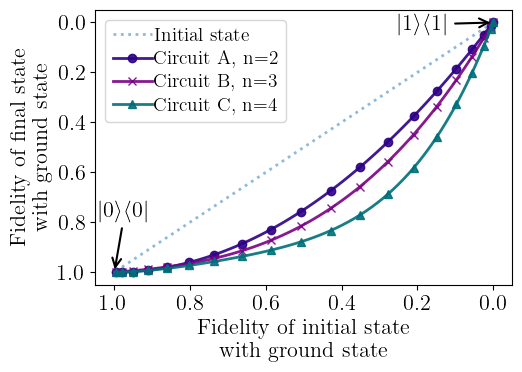

In [14]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.linalg import expm

# Setup
sigma_x = np.array([[0, 1], [1, 0]])
thetas = np.linspace(0, 1, 100)
psis = np.array([expm(-1j * np.pi/2 * sigma_x * t) @ [[0], [1]] for t in thetas])
state_0 = np.array([1, 0], dtype=complex)
target_fidelity = 0.9

# Helper: Fidelity w.r.t. |0⟩
def fidelity_with_0(state):
    rho = state @ state.T.conj() if state.ndim == 2 else state
    return np.real(state_0.conj().T @ rho @ state_0)

# Initial state fidelities and GCI energy
fidelities_original = [fidelity_with_0(psi) for psi in psis]
res_init = [GCI(initial_psi, psi, 1, np.linspace(0.01, 1, 2)).execute_gci()[0][-1] for psi in psis]


# DB-QITE results
def run_dbqite(label_map, k, psis):
    results = {}
    for M, label in label_map.items():
        s_vals = optimal_s_Mk[M-1][:k]
        energies = [GCI(QITE_dme_select_M(M), psi, None, s_vals).execute_gci()[0][-1] for psi in psis]
        results[label] = [(1 - E) / 2 for E in energies]
    return results


dict_fid_RGCI_1 = run_dbqite({1: 'Circuit A, n=2', 2: 'Circuit B, n=3'}, k=1, psis=psis)
dict_fid_RGCI_2 = run_dbqite({1: 'Circuit C, n=4'}, k=2, psis=psis)

# Plot
fig, ax = plt.subplots(figsize=(5.5, 4))
ax.plot(fidelities_original, fidelities_original, label="Initial state", alpha=0.5, linestyle=':')

color = ['#2c0084', '#7a0085', '#006f7a', 'C0']
markers = ['o', 'x', '^']

for i, (label, fidelities) in enumerate(dict_fid_RGCI_1.items()):
    ax.plot(fidelities_original, fidelities, label=label, color=color[i],
            marker=markers[i], markevery=5, markersize=6, alpha=0.9)

for i, (label, fidelities) in enumerate(dict_fid_RGCI_2.items()):
    ax.plot(fidelities_original, fidelities, label=label, color=color[i+2],
            marker=markers[i+2], markevery=5, markersize=6, alpha=0.9)

# Reverse axes: higher overlap → left/lower corner
plt.gca().invert_xaxis()
plt.gca().invert_yaxis()
# ax.axhline(y=target_fidelity, color='k', alpha=0.6, linestyle='--', label=f'Target F = {target_fidelity}')

# Labels and legend
ax.set_xlabel('Fidelity of initial state\nwith ground state')
ax.set_ylabel('Fidelity of final state\nwith ground state')
ax.legend()

# Annotate |1⟩ and |0⟩ 
ax.annotate(r'$|1\rangle\langle 1|$', xy=(fidelities_original[0], fidelities[0]), 
            xytext=(fidelities_original[0]+0.25, fidelities[0]+0.03), arrowprops=dict(arrowstyle='->', lw=1.5))
ax.annotate(r'$|0\rangle\langle 0|$', xy=(fidelities_original[-1], fidelities[-1]), 
            xytext=(fidelities_original[-1]+0.04, fidelities[-1]-0.22), arrowprops=dict(arrowstyle='->', lw=1.5))

plt.tight_layout()
plt.savefig(f'plots/3_circuit_fid.pdf')


0 0 0.01 --- Warning edge of interval reached
0 0 0.01 --- Warning edge of interval reached
0 0 0.01 --- Warning edge of interval reached
0 0 0.01 --- Warning edge of interval reached
0 0 0.01 --- Warning edge of interval reached
0 0 0.01 --- Warning edge of interval reached
0 0 0.01 --- Warning edge of interval reached
0 0 0.01 --- Warning edge of interval reached
0 0 0.01 --- Warning edge of interval reached
0 0 0.01 --- Warning edge of interval reached
0 0 0.01 --- Warning edge of interval reached
0 0 0.01 --- Warning edge of interval reached
0 0 0.01 --- Warning edge of interval reached
0 0 0.01 --- Warning edge of interval reached
0 0 0.01 --- Warning edge of interval reached
0 0 0.01 --- Warning edge of interval reached
0 0 0.01 --- Warning edge of interval reached
0 0 0.01 --- Warning edge of interval reached
0 0 0.01 --- Warning edge of interval reached
0 0 0.01 --- Warning edge of interval reached
0 0 0.01 --- Warning edge of interval reached
0 0 0.01 --- Warning edge of inter

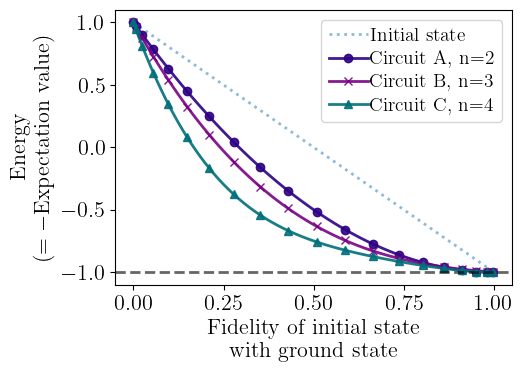

In [15]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.linalg import expm

# Setup
sigma_x = np.array([[0, 1], [1, 0]])
thetas = np.linspace(0, 1, 100)
psis = np.array([expm(-1j * np.pi/2 * sigma_x * t) @ [[0], [1]] for t in thetas])
state_0 = np.array([1, 0], dtype=complex)
target_fidelity = -1

# Helper: Fidelity w.r.t. |0⟩
def fidelity_with_0(state):
    rho = state @ state.T.conj() if state.ndim == 2 else state
    return np.real(state_0.conj().T @ rho @ state_0)

# Initial state fidelities and GCI energy
fidelities_original = [fidelity_with_0(psi) for psi in psis]
res_init = [GCI(initial_psi, psi, 1, np.linspace(0.01, 1, 2)).execute_gci()[0][-1] for psi in psis]

# DB-QITE results
def run_dbqite(label_map, k, psis):
    results = {}
    for M, label in label_map.items():
        s_vals = optimal_s_Mk[M-1][:k]
        energies = [GCI(QITE_dme_select_M(M), psi, None, s_vals).execute_gci()[0][-1] for psi in psis]
        results[label] = energies
    return results


dict_fid_RGCI_1 = run_dbqite({1: 'Circuit A, n=2', 2: 'Circuit B, n=3'}, k=1, psis=psis)
dict_fid_RGCI_2 = run_dbqite({1: 'Circuit C, n=4'}, k=2, psis=psis)

# Plot
fig, ax = plt.subplots(figsize=(5.5, 4))
ax.plot(fidelities_original, res_init, label="Initial state", alpha=0.5, linestyle=':')

color = ['#2c0084', '#7a0085', '#006f7a', 'C0']
markers = ['o', 'x', '^']

for i, (label, energies) in enumerate(dict_fid_RGCI_1.items()):
    ax.plot(fidelities_original, energies, label=label, color=color[i],
            marker=markers[i], markevery=5, markersize=6, alpha=0.9)

for i, (label, energies) in enumerate(dict_fid_RGCI_2.items()):
    ax.plot(fidelities_original, energies, label=label, color=color[i+2],
            marker=markers[i+2], markevery=5, markersize=6, alpha=0.9)

# ax.axvline(0.3)


# Annotations
ax.axhline(y=target_fidelity, color='k', alpha=0.6, linestyle='--')
ax.set_xlabel('Fidelity of initial state\nwith ground state')
ax.set_ylabel('Energy'+'\n'+r'($=-$''Expectation value)')
ax.legend()

ax.annotate(r'$|1\rangle\langle 1|$', 
            xy=(fidelities_original[0], res_init[0] + 1), 
            xytext=(fidelities_original[0] + 0.15, res_init[0] + 0.9),
            arrowprops=dict(arrowstyle='->', lw=1.5))

ax.annotate(r'$|0\rangle\langle 0|$', 
            xy=(fidelities_original[-1], res_init[-1] - 2), 
            xytext=(fidelities_original[-1] - 0.1, res_init[-1] - 1.5),
            arrowprops=dict(arrowstyle='->', lw=1.5))

plt.tight_layout()
plt.savefig(f'plots/energy_QITE_DME_k_2_M_fidelity_final_vs_original.pdf')


0 0 0.01 --- Warning edge of interval reached
0 0 0.01 --- Warning edge of interval reached
0 0 0.01 --- Warning edge of interval reached
0 0 0.01 --- Warning edge of interval reached
0 0 0.01 --- Warning edge of interval reached
0 0 0.01 --- Warning edge of interval reached
0 0 0.01 --- Warning edge of interval reached
0 0 0.01 --- Warning edge of interval reached
0 0 0.01 --- Warning edge of interval reached
0 0 0.01 --- Warning edge of interval reached
0 0 0.01 --- Warning edge of interval reached
0 0 0.01 --- Warning edge of interval reached
0 0 0.01 --- Warning edge of interval reached
0 0 0.01 --- Warning edge of interval reached
0 0 0.01 --- Warning edge of interval reached
0 0 0.01 --- Warning edge of interval reached
0 0 0.01 --- Warning edge of interval reached
0 0 0.01 --- Warning edge of interval reached
0 0 0.01 --- Warning edge of interval reached
0 0 0.01 --- Warning edge of interval reached
0 0 0.01 --- Warning edge of interval reached
0 0 0.01 --- Warning edge of inter

c:\Python\Lib\site-packages\matplotlib\cbook.py:1709: ComplexWarning: Casting complex values to real discards the imaginary part
  return math.isfinite(val)
c:\Python\Lib\site-packages\matplotlib\cbook.py:1345: ComplexWarning: Casting complex values to real discards the imaginary part
  return np.asarray(x, float)


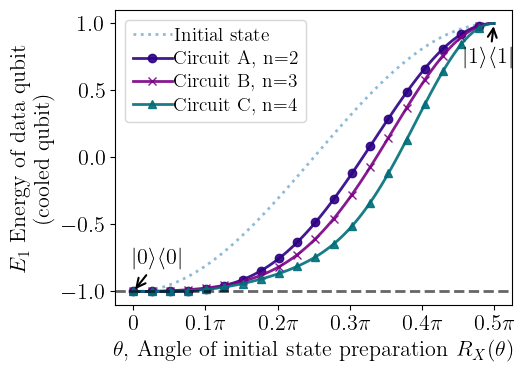

In [19]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.linalg import expm

# Setup
sigma_x = np.array([[0, 1], [1, 0]])
thetas = np.linspace(0, 1, 100)
psis = np.array([expm(-1j * np.pi/2 * sigma_x * t) @ [[1], [0]] for t in thetas])
state_0 = np.array([1, 0], dtype=complex)
target_fidelity = -1

# Helper: Fidelity w.r.t. |0⟩
def fidelity_with_0(state):
    rho = state @ state.T.conj() if state.ndim == 2 else state
    return np.real(state_0.conj().T @ rho @ state_0)

# Initial state fidelities and GCI energy
fidelities_original = [fidelity_with_0(psi) for psi in psis]
res_init = [GCI(initial_psi, psi, 1, np.linspace(0.01, 1, 2)).execute_gci()[0][-1] for psi in psis]

# DB-QITE results
def run_dbqite(label_map, k, psis):
    results = {}
    for M, label in label_map.items():
        s_vals = optimal_s_Mk[M-1][:k]
        energies = [GCI(QITE_dme_select_M(M), psi, None, s_vals).execute_gci()[0][-1] for psi in psis]
        results[label] = energies
    return results


dict_fid_RGCI_1 = run_dbqite({1: 'Circuit A, n=2', 2: 'Circuit B, n=3'}, k=1, psis=psis)
dict_fid_RGCI_2 = run_dbqite({1: 'Circuit C, n=4'}, k=2, psis=psis)

# Plot
fig, ax = plt.subplots(figsize=(5.5, 4))
ax.plot(thetas*np.pi/2, res_init, label="Initial state", alpha=0.5, linestyle=':')

color = ['#2c0084', '#7a0085', '#006f7a', 'C0']
markers = ['o', 'x', '^']

for i, (label, energies) in enumerate(dict_fid_RGCI_1.items()):
    ax.plot(thetas*np.pi/2, energies, label=label, color=color[i],
            marker=markers[i], markevery=5, markersize=6, alpha=0.9)

for i, (label, energies) in enumerate(dict_fid_RGCI_2.items()):
    ax.plot(thetas*np.pi/2, energies, label=label, color=color[i+2],
            marker=markers[i+2], markevery=5, markersize=6, alpha=0.9)

# Annotations
ax.axhline(y=target_fidelity, color='k', alpha=0.6, linestyle='--')
ax.set_xlabel(r'$\theta,$ Angle of initial state preparation $R_X(\theta)$')
ax.set_ylabel(r'$E_1$ Energy of data qubit'+'\n (cooled qubit)')
ax.legend()

ax.annotate(r'$|1\rangle\langle 1|$', 
            xy=((thetas*np.pi/2)[-1], res_init[-1]), 
            xytext=((thetas*np.pi/2)[-1]-0.13, res_init[-1]-0.3),
            arrowprops=dict(arrowstyle='->', lw=1.5))

ax.annotate(r'$|0\rangle\langle 0|$', 
            xy=((thetas*np.pi/2)[0], res_init[0]), 
            xytext=((thetas*np.pi/2)[0], res_init[0]+0.2),
            arrowprops=dict(arrowstyle='->', lw=1.5))

plt.tight_layout()
# plt.savefig(f'plots/energy_QITE_DME_k_2_M_fidelity_final_vs_original.pdf')

import matplotlib.ticker as ticker

# Define ticks and labels
ticks = np.linspace(0, np.pi/2, 6)  # [0, 0.1, ..., 1.0]
tick_labels = [r'$0$', r'$0.1\pi$', r'$0.2\pi$', r'$0.3\pi$', r'$0.4\pi$', 
               r'$0.5\pi$', 
            #    r'$0.6\pi$', r'$0.7\pi$', r'$0.8\pi$', r'$0.9\pi$', r'$\pi$'
               ]

# Apply to x-axis
ax.set_xticks(ticks)
ax.set_xticklabels(tick_labels)
plt.savefig(f'plots/3_circuit_energy_theta.pdf')